# BCSE331P – Exploratory Data Analysis
## Assessment 5: Multivariate Analysis
**Dataset:** `recid.csv` (1445 rows; columns: rownames, black, alcohol, drugs, super, married, felon, workprg, property, person, priors, educ, rules, age, tserved, follow, durat, cens, ldurat).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/recid.csv"

**Q1. Load the dataset; identify numerical and categorical variables**

In [2]:
df = pd.read_csv(URL)

In [3]:
# readable labels for the 0/1 coded columns (used for categorical analysis)
df["race"] = df["black"].map({1: "Black", 0: "Other"})
df["felon_status"] = df["felon"].map({1: "Felon", 0: "Non-felon"})
df["supervised"] = df["super"].map({1: "Supervised", 0: "Unsupervised"})
df["marital"] = df["married"].map({1: "Married", 0: "Single"})
df["offense"] = np.select([df["property"] == 1, df["person"] == 1], ["Property", "Person"], "Other")

In [4]:
numerical = ["priors", "educ", "rules", "age", "tserved", "follow", "durat", "ldurat"]
categorical = ["black", "alcohol", "drugs", "super", "married", "felon", "workprg", "property", "person", "cens"]  # 0/1 coded
print("Numerical  :", numerical)
print("Categorical:", categorical, "(+ labelled: race, felon_status, supervised, marital, offense)")
df.dtypes

Numerical  : ['priors', 'educ', 'rules', 'age', 'tserved', 'follow', 'durat', 'ldurat']
Categorical: ['black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'cens'] (+ labelled: race, felon_status, supervised, marital, offense)


,0
rownames,int64
black,int64
alcohol,int64
drugs,int64
super,int64
married,int64
felon,int64
workprg,int64
property,int64
person,int64


**Q2. Scatter plot – 3 variables (x = age, y = tserved, colour = race)**

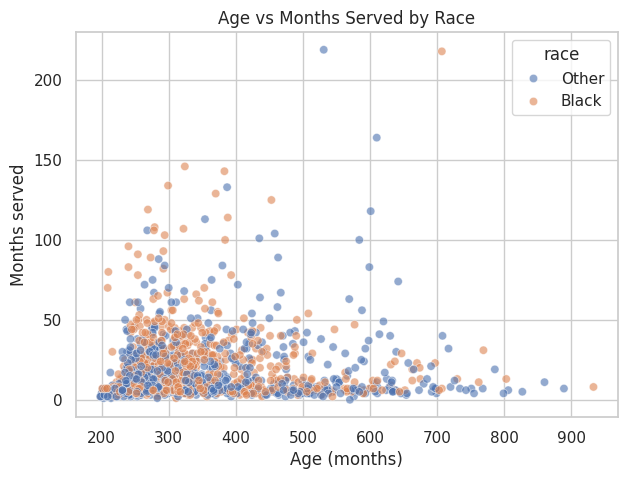

In [5]:
plt.figure(figsize=(7,5)); sns.scatterplot(data=df, x="age", y="tserved", hue="race", alpha=.6)
plt.title("Age vs Months Served by Race"); plt.xlabel("Age (months)"); plt.ylabel("Months served"); plt.show()

**Q3. Scatter plot – 4 variables (colour = race, shape = felon_status)**

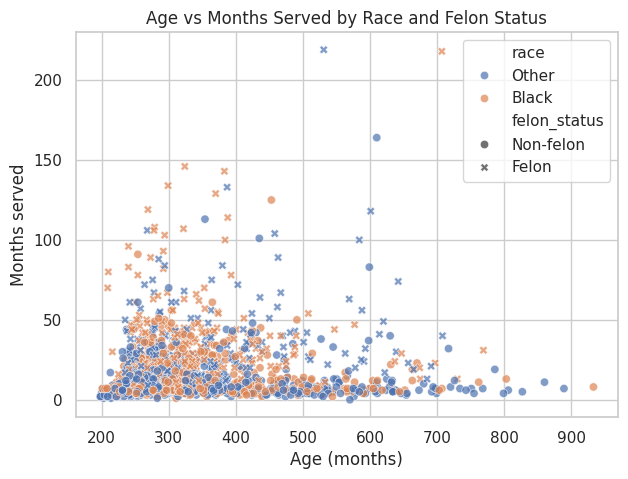

In [6]:
plt.figure(figsize=(7,5)); sns.scatterplot(data=df, x="age", y="tserved", hue="race", style="felon_status", alpha=.7)
plt.title("Age vs Months Served by Race and Felon Status"); plt.xlabel("Age (months)"); plt.ylabel("Months served"); plt.show()

**Q4. Scatter plot – 4 variables (colour = race, size = priors)**

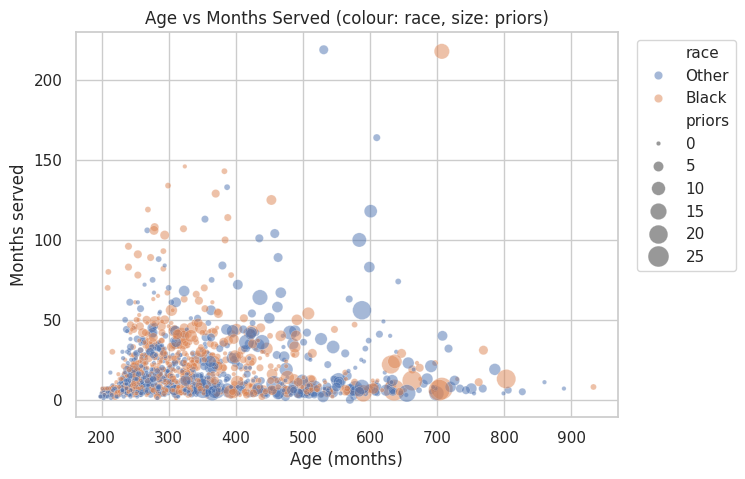

In [7]:
plt.figure(figsize=(7,5)); sns.scatterplot(data=df, x="age", y="tserved", hue="race", size="priors", sizes=(10, 250), alpha=.5)
plt.title("Age vs Months Served (colour: race, size: priors)"); plt.xlabel("Age (months)"); plt.ylabel("Months served")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

**Q5. Bubble plot – x = age, y = tserved, size = priors** (random sample of 150 for clarity)

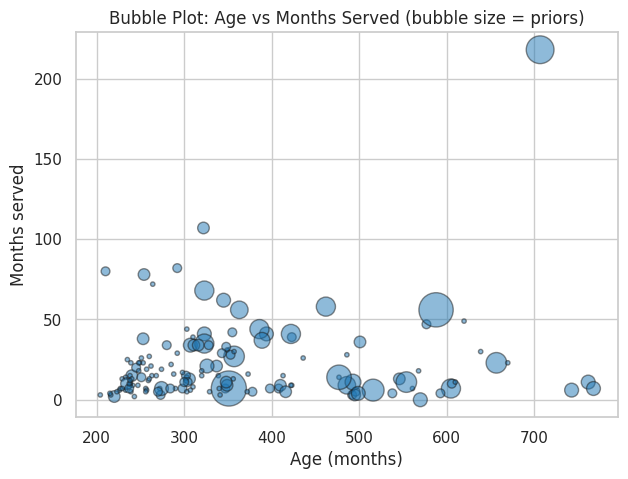

In [8]:
s = df.sample(150, random_state=1)
plt.figure(figsize=(7,5))
plt.scatter(s["age"], s["tserved"], s=s["priors"]*30 + 10, alpha=.5, color="tab:blue", edgecolor="k")
plt.title("Bubble Plot: Age vs Months Served (bubble size = priors)"); plt.xlabel("Age (months)"); plt.ylabel("Months served"); plt.show()

**Q6. Subplots using facet_wrap equivalent (`offense`)**

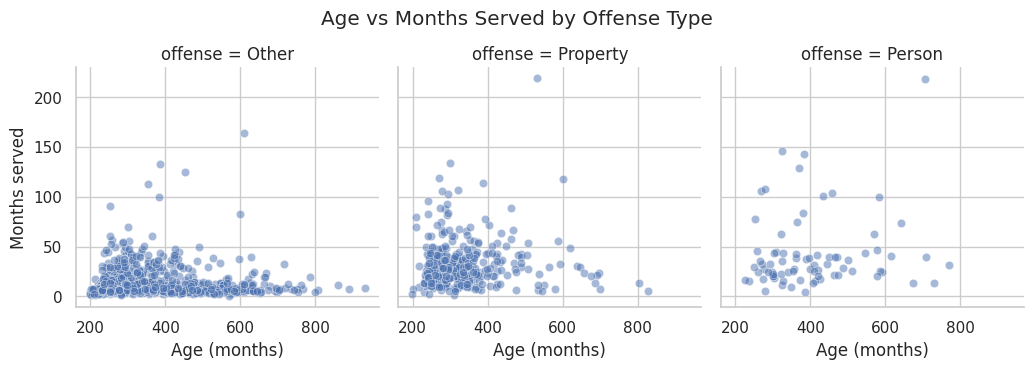

In [9]:
g = sns.relplot(data=df, x="age", y="tserved", col="offense", col_wrap=3, height=3.5, alpha=.5)
g.set_axis_labels("Age (months)", "Months served"); g.fig.suptitle("Age vs Months Served by Offense Type", y=1.05); plt.show()

**Q7. Subplots using facet_grid equivalent (rows = `race`, columns = `felon_status`)**

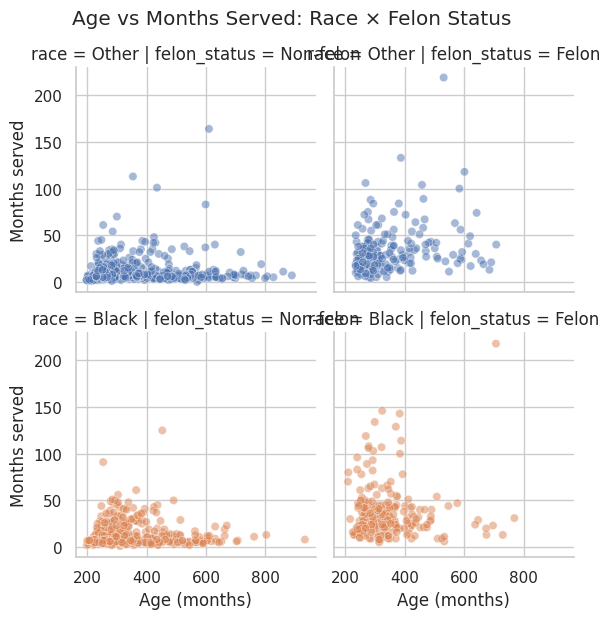

n  mean_age  mean_served  corr_age_served
race  felon_status                                             
Black Felon         250    336.04        35.44             0.02
      Non-felon     451    339.89        13.06            -0.01
Other Felon         204    349.28        33.32             0.25
      Non-felon     540    352.96        11.43             0.04

In [10]:
g = sns.relplot(data=df, x="age", y="tserved", row="race", col="felon_status", height=3, alpha=.5, hue="race", legend=False)
g.set_axis_labels("Age (months)", "Months served"); g.fig.suptitle("Age vs Months Served: Race × Felon Status", y=1.03); plt.show()

# compare patterns across groups
df.groupby(["race", "felon_status"]).agg(n=("age", "size"), mean_age=("age", "mean"), mean_served=("tserved", "mean"),
                                         corr_age_served=("age", lambda x: x.corr(df.loc[x.index, "tserved"]))).round(2)

**Q8. Pairs plot (priors, educ, age, tserved)**

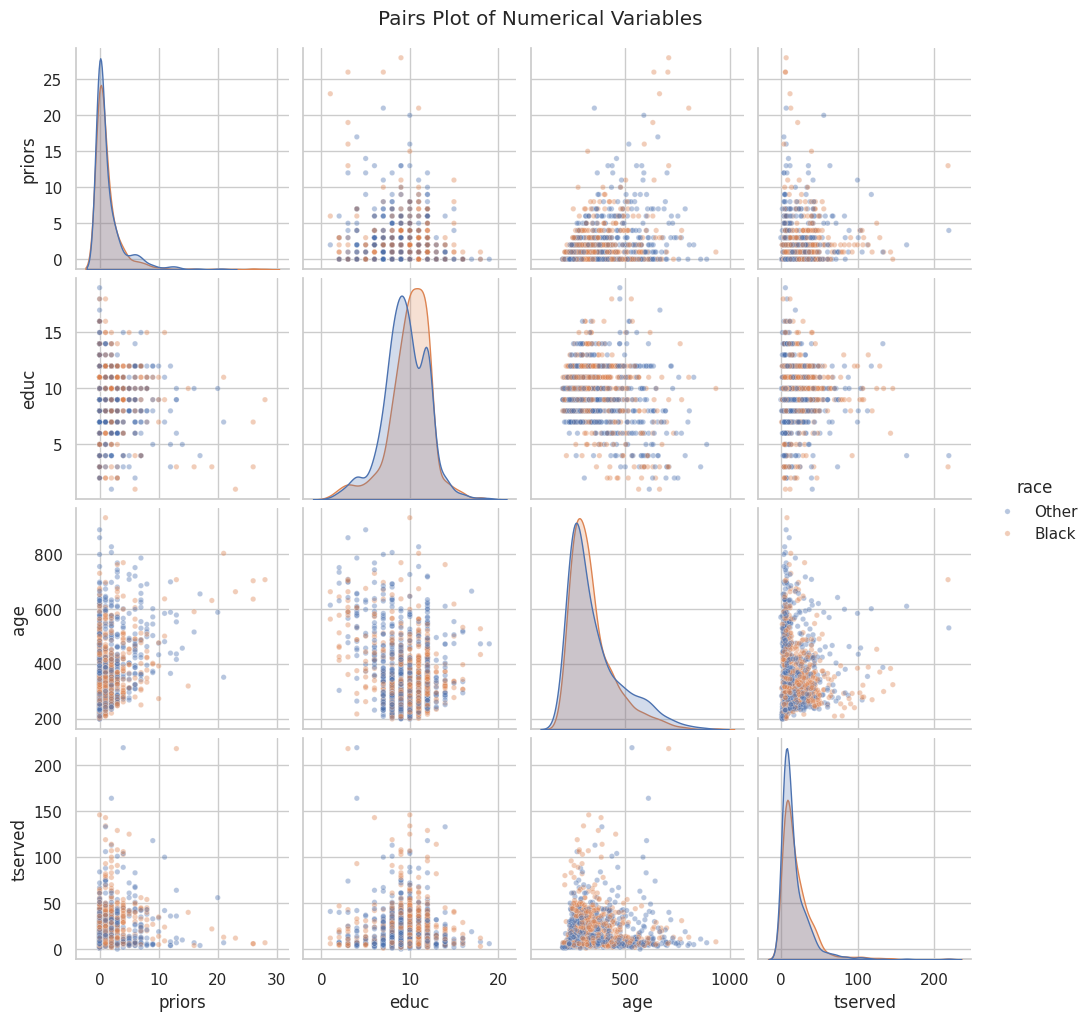

         priors  educ   age  tserved
priors     1.00 -0.18  0.42     0.17
educ      -0.18  1.00 -0.27    -0.05
age        0.42 -0.27  1.00     0.04
tserved    0.17 -0.05  0.04     1.00


In [11]:
g = sns.pairplot(df, vars=["priors", "educ", "age", "tserved"], hue="race", corner=False, plot_kws={"alpha": .4, "s": 15})
g.fig.suptitle("Pairs Plot of Numerical Variables", y=1.02); plt.show()
print(df[["priors", "educ", "age", "tserved"]].corr().round(2))

**Q9. Parallel coordinate plot** (min-max scaled; 200 random observations; coloured by race)

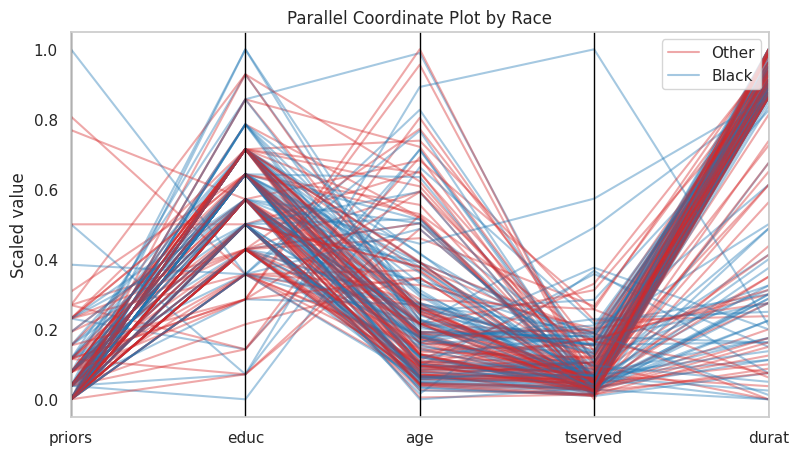

In [12]:
from pandas.plotting import parallel_coordinates
cols = ["priors", "educ", "age", "tserved", "durat"]
s = df.sample(200, random_state=1)[cols + ["race"]].copy()
s[cols] = (s[cols] - s[cols].min()) / (s[cols].max() - s[cols].min())
plt.figure(figsize=(9,5))
parallel_coordinates(s, "race", color=["tab:red", "tab:blue"], alpha=.4)
plt.title("Parallel Coordinate Plot by Race"); plt.ylabel("Scaled value"); plt.show()